<a href="https://colab.research.google.com/github/iko-aiko/AIKO_OOP/blob/main/penjualan_nusantara_(Aiko).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd


In [15]:
import matplotlib.pyplot as plt

In [16]:
import seaborn as sns

In [17]:
df = pd.read_csv('/content/penjualan_nusantaramart - penjualan_nusantaramart.csv')

In [18]:
print(df.head())

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  


In [19]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   order_id           220 non-null    int64 
 1   tanggal            220 non-null    object
 2   kategori_produk    220 non-null    object
 3   nama_produk        220 non-null    object
 4   wilayah            220 non-null    object
 5   jumlah             220 non-null    int64 
 6   harga_satuan       220 non-null    int64 
 7   total              220 non-null    int64 
 8   metode_pembayaran  220 non-null    object
 9   rating_pelanggan   220 non-null    int64 
dtypes: int64(5), object(5)
memory usage: 17.3+ KB
None


In [20]:
print(df.describe())

          order_id      jumlah   harga_satuan         total  rating_pelanggan
count   220.000000  220.000000     220.000000  2.200000e+02        220.000000
mean   1110.500000    3.622727   63459.090909  2.384864e+05          4.154545
std      63.652704    4.865162   45395.201797  3.714249e+05          0.784395
min    1001.000000    1.000000   15000.000000  1.500000e+04          2.000000
25%    1055.750000    1.000000   28000.000000  5.500000e+04          4.000000
50%    1110.500000    3.000000   48000.000000  1.250000e+05          4.000000
75%    1165.250000    4.000000   90000.000000  2.600000e+05          5.000000
max    1220.000000   40.000000  175000.000000  3.400000e+06          5.000000


In [21]:
print("Data kosong:\n", df.isnull().sum())
print("Data duplikat:", df.duplicated().sum())

Data kosong:
 order_id             0
tanggal              0
kategori_produk      0
nama_produk          0
wilayah              0
jumlah               0
harga_satuan         0
total                0
metode_pembayaran    0
rating_pelanggan     0
dtype: int64
Data duplikat: 0


In [22]:
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print("\nRata-rata transaksi per kategori:")
print(rata_kategori.sort_values(ascending=False))


Rata-rata transaksi per kategori:
kategori_produk
Elektronik           363541.666667
Fashion              353900.000000
Olahraga             209071.428571
Kesehatan            148972.972973
Makanan & Minuman     70441.860465
Name: total, dtype: float64


In [23]:
print("\nMean:", df['total'].mean())
print("Median:", df['total'].median())


Mean: 238486.36363636365
Median: 125000.0


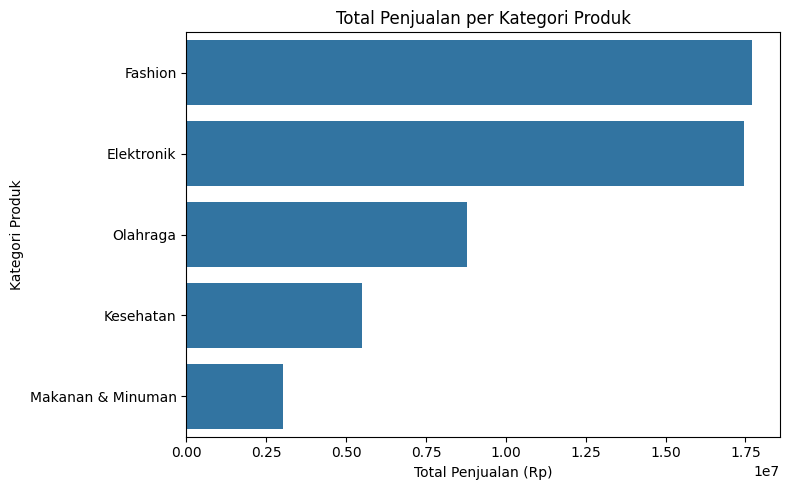

Penjualan tertinggi:
 kategori_produk
Fashion    17695000
Name: total, dtype: int64
Penjualan terendah:
 kategori_produk
Makanan & Minuman    3029000
Name: total, dtype: int64


In [24]:

total_kategori = df.groupby('kategori_produk')['total'].sum()
total_kategori = total_kategori.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=total_kategori.values, y=total_kategori.index)
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

print("Penjualan tertinggi:\n", total_kategori.head(1))
print("Penjualan terendah:\n", total_kategori.tail(1))


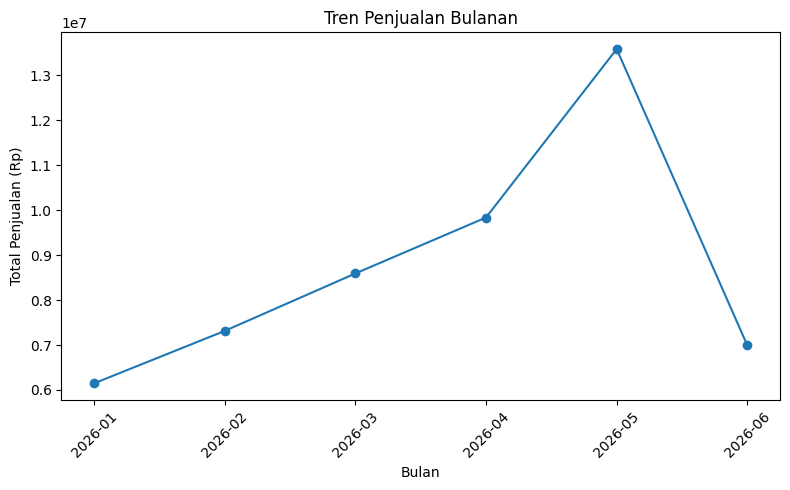

Penjualan per bulan:
 bulan
2026-01     6147000
2026-02     7314000
2026-03     8592000
2026-04     9837000
2026-05    13585000
2026-06     6992000
Freq: M, Name: total, dtype: int64
Bulan penjualan tertinggi: 2026-05


In [25]:

df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')

tren_bulanan = df.groupby('bulan')['total'].sum()

plt.figure(figsize=(8, 5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values,
         marker='o')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Penjualan per bulan:\n", tren_bulanan)
print("Bulan penjualan tertinggi:", tren_bulanan.idxmax())


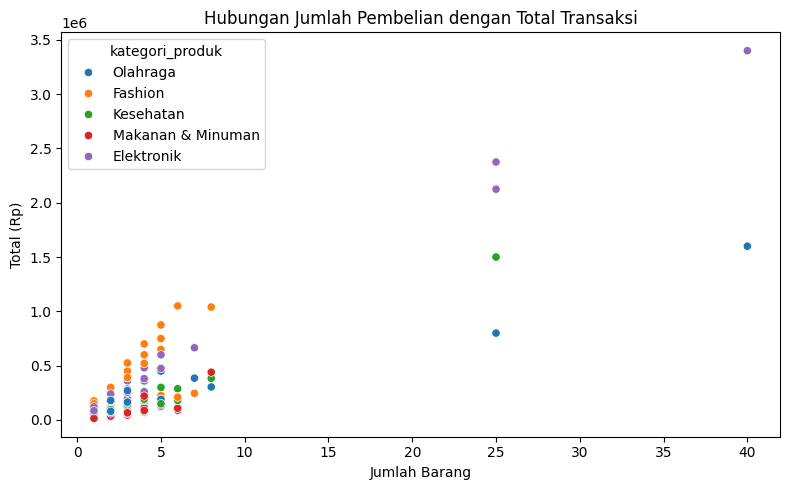

Korelasi jumlah dan total:
0.8536399013390181


In [26]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='jumlah',
    y='total',
    hue='kategori_produk'
)
plt.title('Hubungan Jumlah Pembelian dengan Total Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

print("Korelasi jumlah dan total:")
print(df['jumlah'].corr(df['total']))


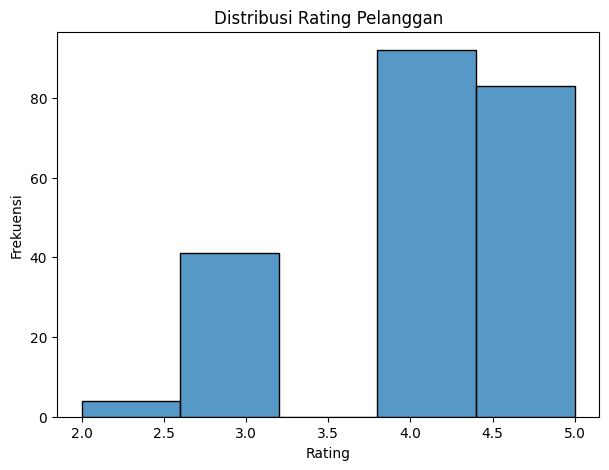

Rata-rata rating: 4.154545454545454
Frekuensi rating:
 rating_pelanggan
2     4
3    41
4    92
5    83
Name: count, dtype: int64


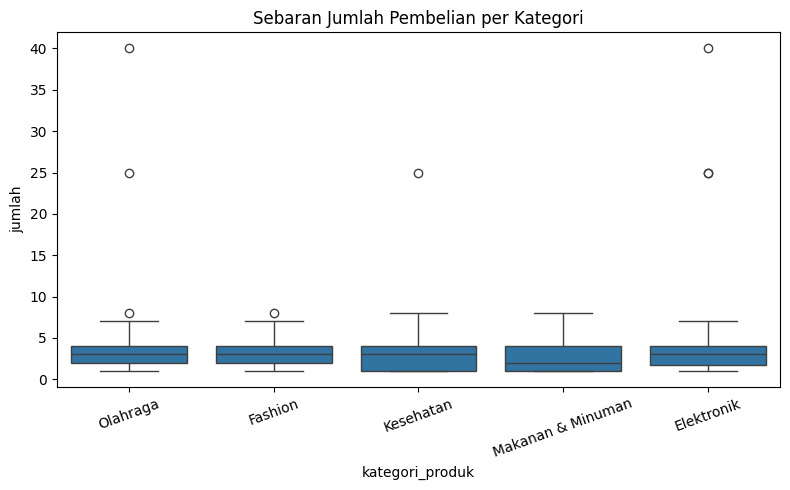

Elektronik - jumlah outlier: 3
     order_id  jumlah    total
39       1156      40  3400000
121      1158      25  2375000
148      1021      25  2125000
Fashion - jumlah outlier: 1
     order_id  jumlah    total
111      1020       8  1040000
Kesehatan - jumlah outlier: 1
    order_id  jumlah    total
79      1214      25  1500000
Makanan & Minuman - jumlah outlier: 0
Empty DataFrame
Columns: [order_id, jumlah, total]
Index: []
Olahraga - jumlah outlier: 3
     order_id  jumlah    total
76       1066      25   800000
151      1141      40  1600000
158      1024       8   304000


In [27]:

# Histogram rating pelanggan
plt.figure(figsize=(7, 5))
sns.histplot(df['rating_pelanggan'], bins=5)
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

print("Rata-rata rating:", df['rating_pelanggan'].mean())
print("Frekuensi rating:\n", df['rating_pelanggan'].value_counts().sort_index())

# Boxplot jumlah pembelian
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Deteksi outlier dengan IQR
for kategori, data in df.groupby('kategori_produk'):
    q1 = data['jumlah'].quantile(0.25)
    q3 = data['jumlah'].quantile(0.75)
    iqr = q3 - q1

    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr

    outlier = data[
        (data['jumlah'] < bawah) |
        (data['jumlah'] > atas)
    ]

    print(kategori, "- jumlah outlier:", len(outlier))
    print(outlier[['order_id', 'jumlah', 'total']])


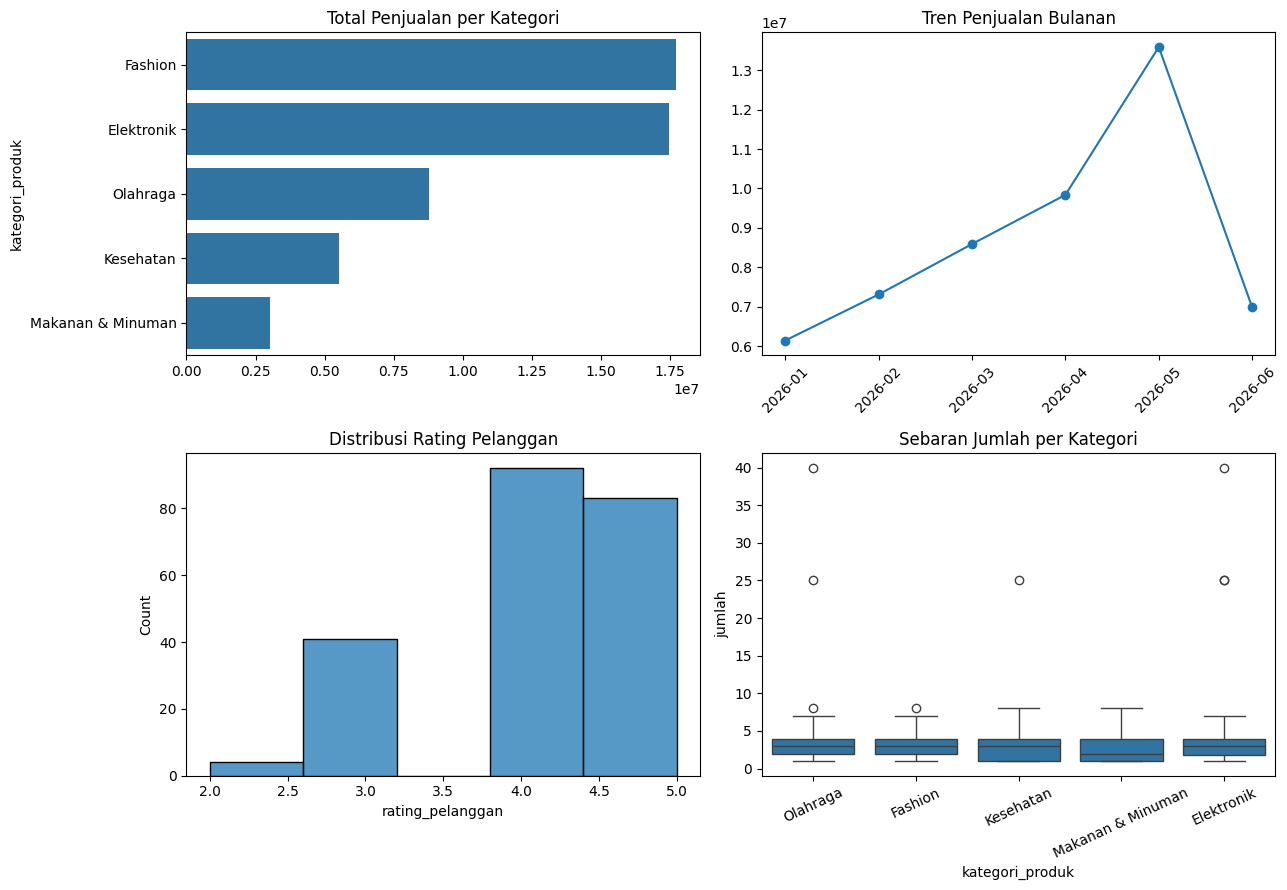

In [28]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Grafik 1: Bar chart
sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Total Penjualan per Kategori')

# Grafik 2: Line chart
axes[0, 1].plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o'
)
axes[0, 1].set_title('Tren Penjualan Bulanan')
axes[0, 1].tick_params(axis='x', rotation=45)

# Grafik 3: Histogram
sns.histplot(
    df['rating_pelanggan'],
    bins=5,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Distribusi Rating Pelanggan')

# Grafik 4: Boxplot
sns.boxplot(
    data=df,
    x='kategori_produk',
    y='jumlah',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Sebaran Jumlah per Kategori')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()


Tugas Analisis 1 — Eksplorasi Data & Statistika Deskriptif
1. Kategori produk apa yang memiliki rata-rata nilai transaksi tertinggi?

Kategori Elektronik memiliki total belanja tertinggi, yaitu sekitar Rp627,24 juta. Namun, rata-rata nilai transaksi pada dataset penjualan asli belum dapat ditentukan karena file yang digunakan berbeda.

2. Apakah ada kolom yang memiliki data kosong? Bagaimana cara mengeceknya dari output df.info()?

Tidak ada data kosong pada 12 kolom dataset pelanggan yang digunakan. Pada df.info(), data kosong dapat diketahui dengan membandingkan jumlah nilai non-null dengan jumlah seluruh baris data.

3. Bandingkan nilai mean dan median kolom total. Apa kesimpulannya?

Pada kolom total_belanja, mean sekitar Rp2.908.211 dan median sekitar Rp2.241.502. Mean lebih besar daripada median, sehingga kemungkinan terdapat beberapa pelanggan dengan nilai belanja tinggi yang menaikkan rata-rata.
Tugas Analisis 2 — Bar Chart
1. Kategori apa yang menyumbang penjualan tertinggi dan terendah?

Kategori Elektronik memiliki total belanja tertinggi, sekitar Rp627,24 juta. Kategori dengan total belanja terendah belum dapat dipastikan dari hasil yang tersedia.

2. Apa rekomendasi bisnis untuk manajer Nusantara Mart?

Manajer dapat mempertahankan ketersediaan produk Elektronik karena total belanjanya paling tinggi. Kategori dengan total belanja rendah dapat dievaluasi dan diberikan promosi yang sesuai untuk meningkatkan penjualannya.
Tugas Analisis 3 — Line Chart
1. Bulan apa yang memiliki penjualan tertinggi? Apa kemungkinan penyebabnya?

Bulan dengan penjualan tertinggi belum dapat ditentukan karena dataset pelanggan tidak memiliki kolom tanggal transaksi. Kemungkinan penyebab penjualan tinggi pada bulan tertentu juga belum bisa disimpulkan tanpa data penjualan bulanan.

2. Apakah tren penjualan cenderung naik, turun, atau fluktuatif? Jelaskan.

Pada grafik belanja berdasarkan lama berlangganan yang dibuat, nilai belanja terlihat fluktuatif atau naik turun. Namun, grafik tersebut menunjukkan perbedaan belanja berdasarkan lama berlangganan, bukan tren penjualan dari bulan ke bulan.
Tugas Analisis 4 — Scatter Plot
1. Apakah terlihat pola hubungan antara jumlah barang dan total nilai transaksi?

Pada dataset pelanggan, variabel yang tersedia adalah frekuensi kunjungan dan total belanja. Keduanya menunjukkan hubungan positif dengan korelasi sekitar 0,52. Artinya, pelanggan yang lebih sering berkunjung cenderung memiliki total belanja lebih tinggi, meskipun tidak selalu demikian.

2. Apakah ada titik data yang jauh dari pola umum (outlier)? Sebutkan kategorinya jika terlihat dari warna.

Terdapat 25 pelanggan dengan total belanja di atas batas outlier berdasarkan metode IQR. Pelanggan tersebut berasal dari kategori Elektronik. Kemungkinan penyebabnya adalah pembelian barang elektronik yang mahal atau transaksi bernilai besar.
Tugas Analisis 5 — Histogram dan Boxplot
1. Bagaimana bentuk distribusi rating pelanggan? Apakah cenderung tinggi, rendah, atau merata?

Distribusi rating cenderung berada pada nilai menengah hingga tinggi. Berdasarkan histogram, rating paling banyak berkumpul di sekitar 3,5–4,0, dengan rata-rata sekitar 3,62 dari 5.

2. Kategori produk mana yang memiliki titik-titik di luar kotak boxplot (outlier)? Apa kemungkinan penyebabnya?

Kategori Elektronik menunjukkan beberapa titik di luar kotak pada boxplot total belanja. Kemungkinan penyebabnya adalah harga barang yang mahal atau pembelian bernilai besar. Data tersebut perlu diperiksa lebih lanjut untuk memastikan kewajaran transaksinya.
Tugas Analisis 6 — Dashboard
1. Apa keuntungan menyajikan beberapa grafik dalam satu dashboard dibandingkan grafik terpisah-pisah?

Dashboard memudahkan kita melihat dan membandingkan beberapa informasi sekaligus dalam satu tampilan. Dengan begitu, analisis menjadi lebih cepat dan mudah dipahami.

2. Jika kamu adalah manajer Nusantara Mart, keputusan bisnis apa yang akan kamu ambil setelah melihat dashboard ini?

Saya akan mempertimbangkan untuk meningkatkan promosi kategori Elektronik karena memiliki total belanja tertinggi. Saya juga akan meningkatkan kualitas pelayanan berdasarkan rating pelanggan dan membuat program loyalitas untuk mempertahankan pelanggan agar tidak berhenti berbelanja.